# Social-Spam Account Detection Using Apache Spark and PySpark

## 1. Project Overview

**Objective:** Analyze social media user data and develop a machine-learning approach to identify spam accounts.

**Tools:** Python, Apache Spark, PySpark, Jupyter Notebook, and Matplotlib.

**Workflow:** Data loading → Data analysis → Data cleaning → Data transformation → Visualization → Machine learning → Model evaluation.

**Dataset:** Social media user information and related CSV files.

**Target variable:** `is_spammer`, where `1` represents a spam account and `-1` represents a non-spam account in the labeled records.

# Social-Spam Account Detection Using Apache Spark and PySpark

## 1. Introduction

Social media platforms can contain spam accounts that publish unwanted content or engage in suspicious activity. This project analyzes social media user data and explores machine-learning techniques for identifying spam accounts.

## 2. Objectives

- Load and inspect social media datasets using PySpark.
- Analyze data quality, missing values, and duplicate records.
- Clean and transform data for analysis.
- Perform distributed data operations using Apache Spark.
- Visualize the dataset using charts.
- Apply the machine-learning algorithms listed in Unit VI.
- Evaluate models using the appropriate performance metrics.

## 3. Tools and Technologies

- Python
- Apache Spark and PySpark
- Jupyter Notebook
- Matplotlib

In [1]:
import os
from pyspark.sql import SparkSession

spark_temp = r"C:\Spark\tmp"
os.makedirs(spark_temp, exist_ok=True)

spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("SocialSpamDetection")
    .config("spark.local.dir", spark_temp)
    .config("spark.driver.memory", "2g")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print("Spark version:", spark.version)
print("Spark test:", spark.range(5).count())
print("Spark temporary directory:", spark_temp)

Spark version: 3.5.9
Spark test: 5
Spark temporary directory: C:\Spark\tmp


In [2]:
from pathlib import Path
import csv

from pyspark.sql import SparkSession
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
spark = (
    SparkSession.builder
    .appName("SocialSpamDetection")
    .master("local[*]")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

sc = spark.sparkContext

print("Spark session created successfully!")
print("Spark version:", spark.version)
print("Application name:", spark.sparkContext.appName)

Spark session created successfully!
Spark version: 3.5.9
Application name: SocialSpamDetection


In [4]:
project_path = Path.cwd().parent
dataset_folder = project_path / "dataset" / "original"

print("Project folder:", project_path)
print("Dataset folder:", dataset_folder)
print("\nDataset folder exists:", dataset_folder.exists())

csv_files = sorted(dataset_folder.glob("*.csv"))

print("\nCSV files found:", len(csv_files))

for file in csv_files:
    print(f"{file.name} — {file.stat().st_size:,} bytes")

Project folder: c:\Users\Zaki\Social-Spam-Detection
Dataset folder: c:\Users\Zaki\Social-Spam-Detection\dataset\original

Dataset folder exists: True

CSV files found: 4
follower_followee.csv — 11,826,938 bytes
post.csv — 9,626 bytes
user_post.csv — 6,108,269 bytes
weibo_user.csv — 157,037 bytes


In [5]:
dataset_info = {}

for file in csv_files:
    rdd = sc.textFile(file.as_posix())

    header = rdd.first()
    total_lines = rdd.count()
    data_count = total_lines - 1

    dataset_info[file.name] = {
        "path": file.as_posix(),
        "header": header,
        "records": data_count
    }

    print("=" * 70)
    print("File:", file.name)
    print("Columns:", header)
    print("Data records:", data_count)

File: follower_followee.csv
Columns: id,follower,follower_id,followee,followee_id,guanzhu,fensi,post_num,gender,first_or_last
Data records: 142368
File: post.csv
Columns: post_id,scratch_time,post_time,content,image,poster,poster_id,poster_url,repost_num,comment_num,repost_post_id
Data records: 35
File: user_post.csv
Columns: post_id,post_time,content,poster_id,poster_url,repost_num,comment_num,repost_post_id,inner_flag
Data records: 48813
File: weibo_user.csv
Columns: user_id,user_name,user_image,gender,class,message,post_num,follower_num,followee_num,is_spammer
Data records: 781


In [6]:
from IPython.display import display
import pandas as pd

summary_rows = []

for filename, info in dataset_info.items():
    summary_rows.append({
        "Dataset": filename,
        "Number of Records": info["records"],
        "Number of Columns": len(next(csv.reader([info["header"]]))),
        "Column Names": info["header"]
    })

summary_df = pd.DataFrame(summary_rows)

display(summary_df)

,Dataset,Number of Records,Number of Columns,Column Names
0,follower_followee.csv,142368,10,"id,follower,follower_id,followee,followee_id,g..."
1,post.csv,35,11,"post_id,scratch_time,post_time,content,image,p..."
2,user_post.csv,48813,9,"post_id,post_time,content,poster_id,poster_url..."
3,weibo_user.csv,781,10,"user_id,user_name,user_image,gender,class,mess..."


In [7]:
import csv

def parse_csv_partition(partition):
    for line in partition:
        try:
            yield next(csv.reader([line]))
        except csv.Error:
            continue

user_file = dataset_folder / "weibo_user.csv"

user_rdd = sc.textFile(user_file.as_posix())
user_header = user_rdd.first()

parsed_users = (
    user_rdd
    .filter(lambda line: line != user_header)
    .mapPartitions(parse_csv_partition)
    .filter(lambda row: len(row) >= 10)
    .cache()
)

label_counts = (
    parsed_users
    .map(lambda row: row[9].strip())
    .map(lambda label: (
        "Spam (1)" if label == "1"
        else "Non-spam (-1)" if label == "-1"
        else "Missing/Other"
    ))
    .countByValue()
)

print("===== SPAM LABEL DISTRIBUTION =====")

for label, count in sorted(label_counts.items()):
    print(f"{label}: {count}")

print("Total records:", sum(label_counts.values()))

===== SPAM LABEL DISTRIBUTION =====
Missing/Other: 602
Non-spam (-1): 66
Spam (1): 113
Total records: 781


In [8]:
print("Label distribution:")

for label, count in sorted(label_counts.items()):
    print(f"{label}: {count}")

Label distribution:
Missing/Other: 602
Non-spam (-1): 66
Spam (1): 113


In [9]:
import csv
from collections import Counter

def parse_csv_partition(partition):
    for line in partition:
        try:
            yield next(csv.reader([line]))
        except csv.Error:
            continue

user_file = dataset_folder / "weibo_user.csv"

user_rdd = sc.textFile(user_file.as_posix())
user_header = user_rdd.first()
columns = next(csv.reader([user_header]))

parsed_users = (
    user_rdd
    .filter(lambda line: line != user_header)
    .mapPartitions(parse_csv_partition)
    .cache()
)

# Count missing values in each column
missing_counts = (
    parsed_users
    .flatMap(
        lambda row: [
            (columns[i], 1)
            for i in range(min(len(row), len(columns)))
            if row[i].strip() == ""
        ]
    )
    .countByKey()
)

print("===== MISSING VALUE ANALYSIS =====")

for column in columns:
    print(f"{column}: {missing_counts.get(column, 0)}")

===== MISSING VALUE ANALYSIS =====
user_id: 0
user_name: 0
user_image: 0
gender: 0
class: 0
message: 1
post_num: 0
follower_num: 0
followee_num: 0
is_spammer: 602


In [10]:
# Convert each CSV row from a list into a tuple
# so Spark can compare rows for duplicates.

rows_as_tuples = parsed_users.map(lambda row: tuple(row))

total_records = rows_as_tuples.count()
unique_records = rows_as_tuples.distinct().count()
duplicate_records = total_records - unique_records

print("===== DUPLICATE RECORD ANALYSIS =====")
print("Total records:", total_records)
print("Unique records:", unique_records)
print("Duplicate records:", duplicate_records)

===== DUPLICATE RECORD ANALYSIS =====
Total records: 781
Unique records: 781
Duplicate records: 0


In [11]:
# Count occurrences of each user ID
user_id_counts = (
    parsed_users
    .filter(lambda row: len(row) > 0 and row[0].strip() != "")
    .map(lambda row: (row[0].strip(), 1))
    .reduceByKey(lambda a, b: a + b)
    .filter(lambda item: item[1] > 1)
    .collect()
)

print("===== DUPLICATE USER ID ANALYSIS =====")
print("User IDs appearing more than once:", len(user_id_counts))

if user_id_counts:
    print("\nDuplicate user IDs:")
    for user_id, count in user_id_counts[:10]:
        print(f"{user_id}: {count} records")
else:
    print("No duplicate user IDs found.")
    

===== DUPLICATE USER ID ANALYSIS =====
User IDs appearing more than once: 0
No duplicate user IDs found.


In [12]:
# Count blank values in each column
missing_counts = (
    parsed_users
    .flatMap(
        lambda row: [
            (i, 1)
            for i, value in enumerate(row)
            if value.strip() == ""
        ]
    )
    .countByKey()
)

columns = next(csv.reader([user_header]))

missing_summary = pd.DataFrame([
    {
        "Column": column,
        "Missing Values": missing_counts.get(i, 0),
        "Missing Percentage (%)": round(
            missing_counts.get(i, 0) / 781 * 100, 2
        )
    }
    for i, column in enumerate(columns)
])

display(missing_summary)

,Column,Missing Values,Missing Percentage (%)
0,user_id,0,0.00
1,user_name,0,0.00
2,user_image,0,0.00
3,gender,0,0.00
4,class,0,0.00
5,message,1,0.13
6,post_num,0,0.00
7,follower_num,0,0.00
8,followee_num,0,0.00
9,is_spammer,602,77.08


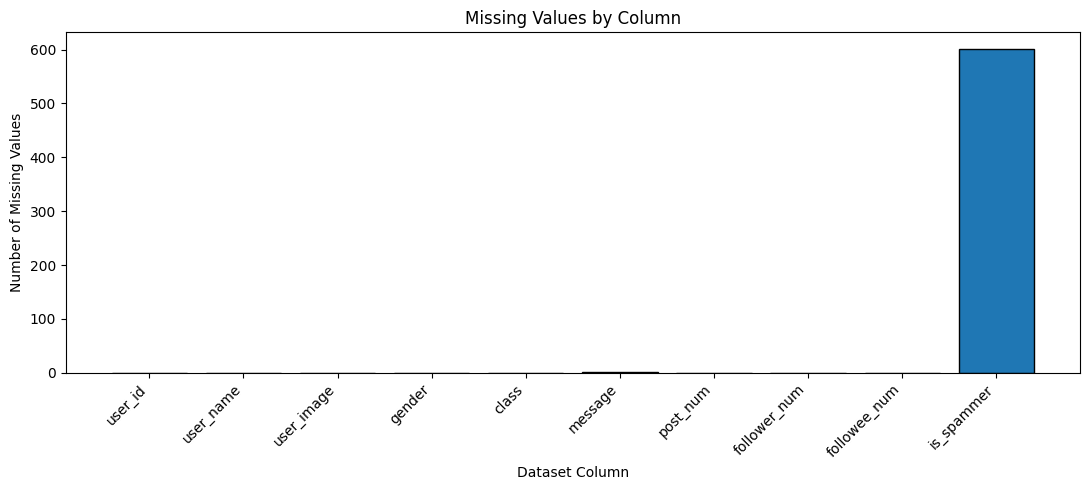

In [13]:
plt.figure(figsize=(11, 5))

plt.bar(
    missing_summary["Column"],
    missing_summary["Missing Values"],
    edgecolor="black"
)

plt.title("Missing Values by Column")
plt.xlabel("Dataset Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    "../results/missing_values.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
import csv

# Column positions in weibo_user.csv
numeric_columns = {
    "post_num": 6,
    "follower_num": 7,
    "followee_num": 8
}

validation_results = []

for column_name, column_index in numeric_columns.items():
    stats = (
        parsed_users
        .map(lambda row: row[column_index].strip()
             if len(row) > column_index else "")
        .map(lambda value: (
            1 if value == "" else 0,
            1 if value != "" and not value.isdigit() else 0,
            1 if value.isdigit() and int(value) < 0 else 0
        ))
        .reduce(lambda a, b: tuple(x + y for x, y in zip(a, b)))
    )

    validation_results.append({
        "Column": column_name,
        "Missing": stats[0],
        "Non-numeric": stats[1],
        "Negative": stats[2]
    })

validation_df = pd.DataFrame(validation_results)
display(validation_df)

,Column,Missing,Non-numeric,Negative
0,post_num,0,0,0
1,follower_num,0,0,0
2,followee_num,0,0,0


In [15]:
columns = next(csv.reader([user_header]))

missing_summary = (
    parsed_users
    .flatMap(
        lambda row: [
            (columns[i], 1)
            for i, value in enumerate(row[:len(columns)])
            if value.strip() == ""
        ]
    )
    .countByKey()
)

missing_df = pd.DataFrame([
    {
        "Column": col,
        "Missing Values": missing_summary.get(col, 0),
        "Missing Percentage (%)": round(
            missing_summary.get(col, 0) / parsed_users.count() * 100, 2
        )
    }
    for col in columns
])

display(missing_df)

,Column,Missing Values,Missing Percentage (%)
0,user_id,0,0.00
1,user_name,0,0.00
2,user_image,0,0.00
3,gender,0,0.00
4,class,0,0.00
5,message,1,0.13
6,post_num,0,0.00
7,follower_num,0,0.00
8,followee_num,0,0.00
9,is_spammer,602,77.08


Total users
781




is_spammer — target label
602 missing (77.08%)
These records cannot be used as labeled examples for supervised spam classification.




message
1 missing (0.13%)
We can leave this field out of our initial model, so no replacement is needed for it.

In [18]:
from pathlib import Path

project_path = Path.cwd().parent
results_folder = project_path / "results"
results_folder.mkdir(parents=True, exist_ok=True)

print("Results folder:", results_folder)
print("Folder exists:", results_folder.exists())

Results folder: c:\Users\Zaki\Social-Spam-Detection\results
Folder exists: True


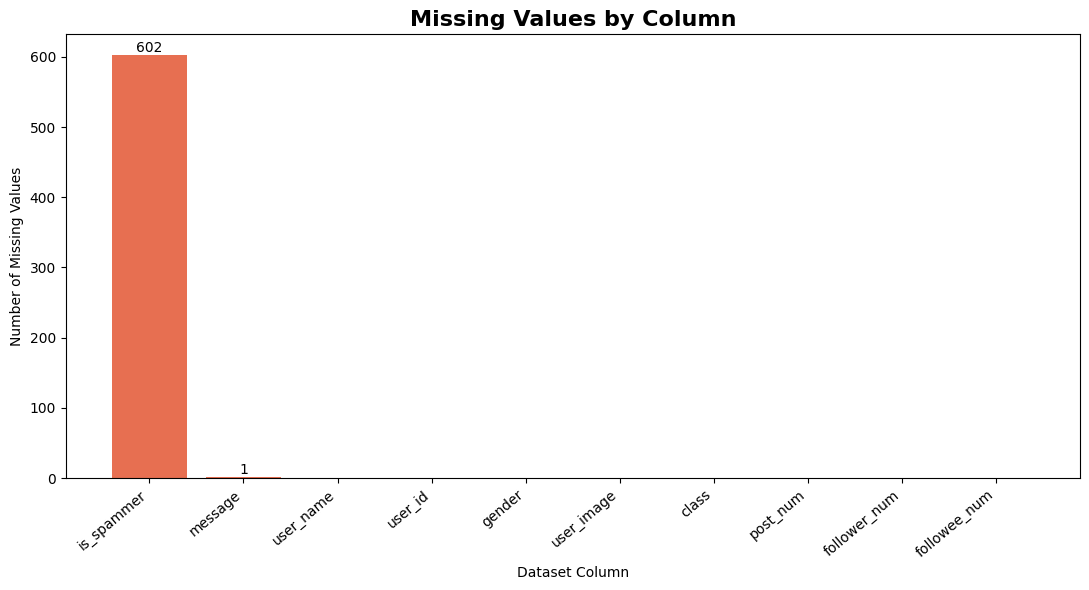

In [19]:
import matplotlib.pyplot as plt

plot_df = missing_df.sort_values(
    "Missing Values", ascending=False
)

plt.figure(figsize=(11, 6))

bars = plt.bar(
    plot_df["Column"],
    plot_df["Missing Values"],
    color=[
        "#e76f51" if value > 0 else "#2a9d8f"
        for value in plot_df["Missing Values"]
    ]
)

plt.title(
    "Missing Values by Column",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Dataset Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=40, ha="right")

for bar in bars:
    value = int(bar.get_height())
    if value > 0:
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value,
            str(value),
            ha="center",
            va="bottom"
        )

plt.tight_layout()

results_folder.mkdir(parents=True, exist_ok=True)
plt.savefig(
    str(results_folder / "missing_values.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Data cleaning

In [ ]:
import csv

def inspect_row(line):
    try:
        return next(csv.reader([line]))
    except csv.Error:
        return []

raw_lines = (
    sc.textFile((dataset_folder / "weibo_user.csv").as_posix())
)

header_line = raw_lines.first()

data_rows = raw_lines.filter(lambda line: line != header_line)

row_lengths = (
    data_rows
    .map(inspect_row)
    .map(lambda row: (len(row), 1))
    .reduceByKey(lambda a, b: a + b)
    .collect()
)

print("===== CSV ROW STRUCTURE CHECK =====")
print("Expected columns: 10")

for length, count in sorted(row_lengths):
    print(f"Rows with {length} columns: {count}")

===== CSV ROW STRUCTURE CHECK =====
Expected columns: 10
Rows with 10 columns: 781


In [ ]:
duplicate_ids = (
    parsed_users
    .filter(lambda row: len(row) >= 1 and row[0].strip() != "")
    .map(lambda row: (row[0].strip(), 1))
    .reduceByKey(lambda a, b: a + b)
    .filter(lambda item: item[1] > 1)
    .collect()
)

print("===== USER ID DUPLICATE CHECK =====")
print("Duplicate user IDs:", len(duplicate_ids))

if duplicate_ids:
    for user_id, count in duplicate_ids[:10]:
        print(f"User ID {user_id}: {count} records")
else:
    print("No duplicate user IDs found.")

===== USER ID DUPLICATE CHECK =====
Duplicate user IDs: 0
No duplicate user IDs found.


In [ ]:
from pathlib import Path
import pandas as pd

results_folder = project_path / "results"
results_folder.mkdir(parents=True, exist_ok=True)

quality_report = pd.DataFrame([
    {
        "Check": "Total source records",
        "Result": 781
    },
    {
        "Check": "Exact duplicate rows",
        "Result": 0
    },
    {
        "Check": "Missing spam labels",
        "Result": 602
    },
    {
        "Check": "Duplicate user IDs",
        "Result": len(duplicate_ids)
    }
])

display(quality_report)

quality_report.to_csv(
    results_folder / "data_quality_report.csv",
    index=False
)

print("Saved:", results_folder / "data_quality_report.csv")

,Check,Result
0,Total source records,781
1,Exact duplicate rows,0
2,Missing spam labels,602
3,Duplicate user IDs,0


Saved: c:\Users\Zaki\Social-Spam-Detection\results\data_quality_report.csv


Your current results
User records
781

CSV files found
4

Exact duplicate rows
0

Duplicate user IDs
0



Other findings
- All 781 user records have the expected 10 columns.
- One message value is missing.
- 602 is_spammer labels are missing; 179 labels are known.
- The three numerical features passed the initial validity checks.

In [ ]:
with open(user_file, "rb") as file:
    sample = file.read(5000)

for encoding in ["utf-8", "gb18030", "gbk", "cp1252"]:
    try:
        sample.decode(encoding)
        print("Encoding that works:", encoding)
        break
    except UnicodeDecodeError:
        print(encoding, "did not work")

utf-8 did not work
Encoding that works: gb18030


In [20]:
import csv

with open(
    user_file,
    "r",
    encoding="gb18030",
    errors="replace",
    newline=""
) as file:
    reader = csv.DictReader(file)
    original_rows = list(reader)
    original_columns = reader.fieldnames

print("Columns:", original_columns)
print("Original records:", len(original_rows))
print("First row loaded successfully:")
print(original_rows[0])

Columns: ['user_id', 'user_name', 'user_image', 'gender', 'class', 'message', 'post_num', 'follower_num', 'followee_num', 'is_spammer']
Original records: 781
First row loaded successfully:
{'user_id': '1041514813', 'user_name': 'james1002', 'user_image': 'http://tp2.sinaimg.cn/1041514813/180/5708899731/1', 'gender': 'male', 'class': '5', 'message': '   Lv.5     浙江宁波   简介：诚信为本，站的高才能看的远。快乐开心每一天。  ', 'post_num': '1557', 'follower_num': '1421', 'followee_num': '2000', 'is_spammer': ''}


In [21]:
import pandas as pd
from pathlib import Path

# Convert the loaded CSV records into a table
users_df = pd.DataFrame(original_rows, columns=original_columns)

# Remove exact duplicate rows, if any
before_rows = len(users_df)
users_cleaned = users_df.drop_duplicates().copy()
duplicates_removed = before_rows - len(users_cleaned)

# Standardize whitespace in column names and text fields
users_cleaned.columns = users_cleaned.columns.str.strip()

for column in users_cleaned.select_dtypes(include="object").columns:
    users_cleaned[column] = users_cleaned[column].str.strip()

# Convert numeric columns safely
numeric_columns = [
    "post_num", "follower_num", "followee_num", "is_spammer"
]

for column in numeric_columns:
    users_cleaned[column] = pd.to_numeric(
        users_cleaned[column].replace("", pd.NA),
        errors="coerce"
    )

# Keep unknown spam labels missing; do not invent labels
print("===== CLEANING SUMMARY =====")
print("Records before cleaning:", before_rows)
print("Records after cleaning:", len(users_cleaned))
print("Exact duplicate rows removed:", duplicates_removed)
print("Missing spam labels:", users_cleaned["is_spammer"].isna().sum())
print("Missing message values:", users_cleaned["message"].isna().sum())

===== CLEANING SUMMARY =====
Records before cleaning: 781
Records after cleaning: 781
Exact duplicate rows removed: 0
Missing spam labels: 602
Missing message values: 0


In [22]:
results_folder = project_path / "results"
results_folder.mkdir(parents=True, exist_ok=True)

cleaned_file = results_folder / "weibo_user_cleaned.csv"

users_cleaned.to_csv(
    cleaned_file,
    index=False,
    encoding="utf-8-sig"
)

print("Cleaned dataset saved to:", cleaned_file)
print("File exists:", cleaned_file.exists())

Cleaned dataset saved to: c:\Users\Zaki\Social-Spam-Detection\results\weibo_user_cleaned.csv
File exists: True


In [23]:
# Verify the cleaned dataset
print("===== CLEANED DATASET VERIFICATION =====")

print("Rows:", len(users_cleaned))
print("Columns:", len(users_cleaned.columns))
print("Duplicate rows:", users_cleaned.duplicated().sum())
print("Duplicate user IDs:", users_cleaned["user_id"].duplicated().sum())

print("\nColumn data types:")
display(users_cleaned.dtypes.rename("Data Type").to_frame())

print("\nFirst five cleaned records:")
display(users_cleaned.head())

===== CLEANED DATASET VERIFICATION =====
Rows: 781
Columns: 10
Duplicate rows: 0
Duplicate user IDs: 0

Column data types:


,Data Type
user_id,object
user_name,object
user_image,object
gender,object
class,object
message,object
post_num,int64
follower_num,int64
followee_num,int64
is_spammer,float64



First five cleaned records:


,user_id,user_name,user_image,gender,class,message,post_num,follower_num,followee_num,is_spammer
0,1041514813,james1002,http://tp2.sinaimg.cn/1041514813/180/5708899731/1,male,5,Lv.5 浙江宁波 简介：诚信为本，站的高才能看的远。快乐开心每一天。,1557,1421,2000,NaN
1,1046222077,郑钧,http://tp2.sinaimg.cn/1046222077/180/5711167576/1,male,10,北京东城区 简介：且把悲歌欢唱 个性域名： zhengjun 博客地址： ht...,1265,1280571,130,NaN
2,1049591831,波播阿波思密达,http://tp4.sinaimg.cn/1049591831/180/5710224593/0,female,5,Lv.5 吉林松原 1972年12月3日 简介：自由人，快乐族,503,302,968,NaN
3,1062050703,霞儿0109,http://tp4.sinaimg.cn/1062050703/180/1277084329/0,female,9,Lv.9 福建厦门 毕业于 厦门大学 公司 ChinaZ站长之家 ...,281,148,354,NaN
4,1071429143,紫荆花_18423,http://tp4.sinaimg.cn/1071429143/180/400610658...,female,5,Lv.5 广东湛江 毕业于 辽宁师范大学 公司 大学教师 1...,135,1975,2000,NaN


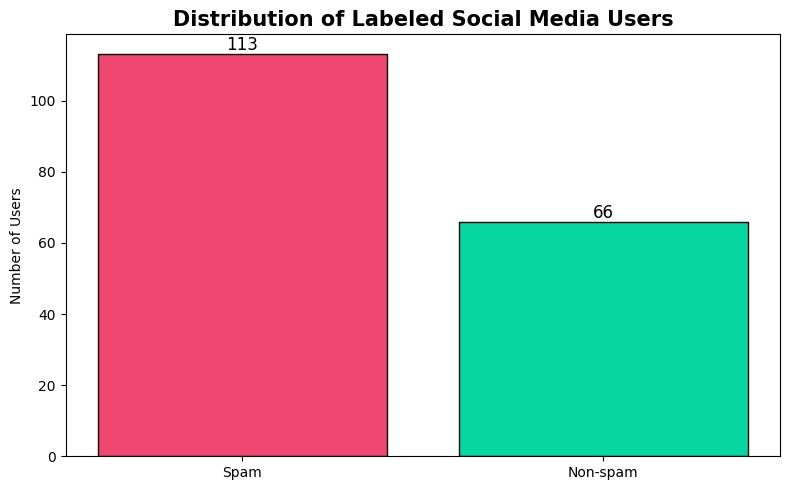

Saved: c:\Users\Zaki\Social-Spam-Detection\results\spam_distribution.png


In [24]:
import matplotlib.pyplot as plt

label_counts = users_cleaned["is_spammer"].value_counts().reindex(
    [1, -1], fill_value=0
)

plt.figure(figsize=(8, 5))
bars = plt.bar(
    ["Spam", "Non-spam"],
    label_counts.values,
    color=["#ef476f", "#06d6a0"],
    edgecolor="black"
)

plt.title("Distribution of Labeled Social Media Users",
          fontsize=15, fontweight="bold")
plt.ylabel("Number of Users")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha="center",
        va="bottom",
        fontsize=12
    )

plt.tight_layout()
plt.savefig(results_folder / "spam_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", results_folder / "spam_distribution.png")

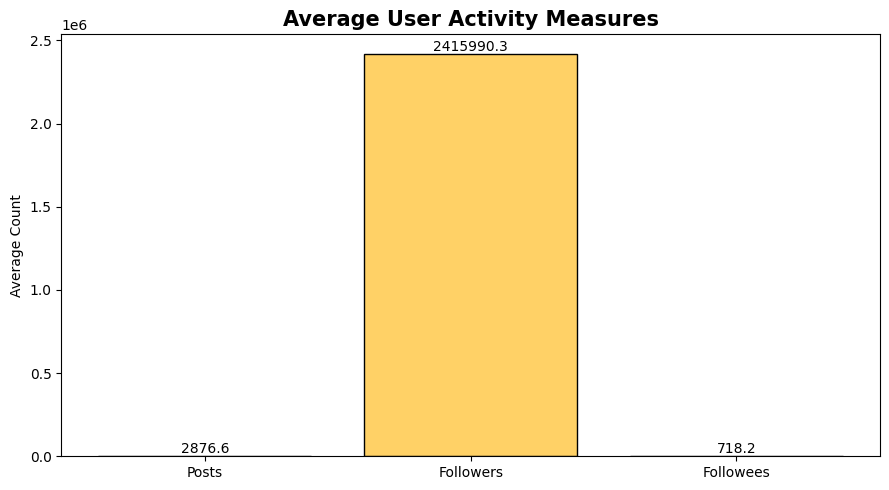

Saved: c:\Users\Zaki\Social-Spam-Detection\results\average_user_activity.png


In [25]:
features = ["post_num", "follower_num", "followee_num"]
feature_means = users_cleaned[features].mean()

plt.figure(figsize=(9, 5))
bars = plt.bar(
    ["Posts", "Followers", "Followees"],
    feature_means.values,
    color=["#118ab2", "#ffd166", "#9b5de5"],
    edgecolor="black"
)

plt.title("Average User Activity Measures",
          fontsize=15, fontweight="bold")
plt.ylabel("Average Count")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.1f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(results_folder / "average_user_activity.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", results_folder / "average_user_activity.png")

In [26]:
import pandas as pd

features = ["post_num", "follower_num", "followee_num"]

correlation_matrix = users_cleaned[features].corr()

display(correlation_matrix.round(3))

,post_num,follower_num,followee_num
post_num,1.000,0.117,0.094
follower_num,0.117,1.000,-0.113
followee_num,0.094,-0.113,1.000


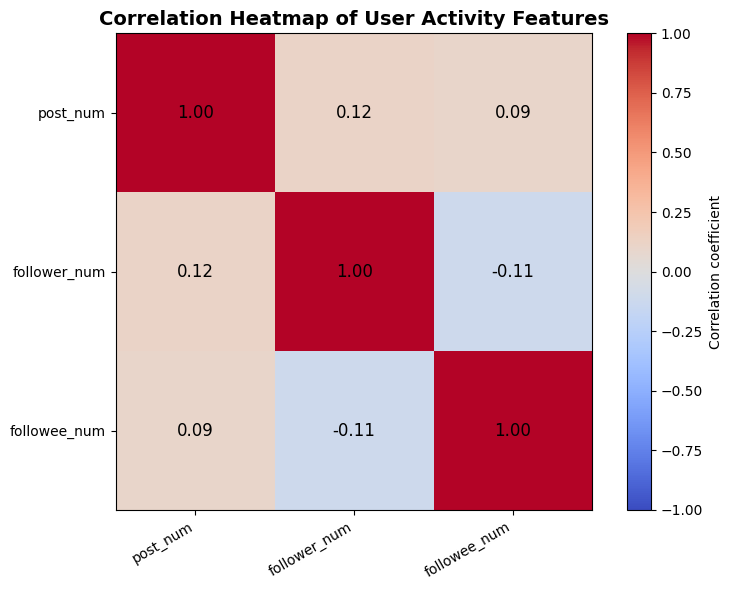

Saved: c:\Users\Zaki\Social-Spam-Detection\results\correlation_heatmap.png


In [27]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(8, 6))

image = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(features)))
ax.set_yticks(range(len(features)))
ax.set_xticklabels(features, rotation=30, ha="right")
ax.set_yticklabels(features)

for i in range(len(features)):
    for j in range(len(features)):
        value = correlation_matrix.iloc[i, j]
        ax.text(
            j, i, f"{value:.2f}",
            ha="center",
            va="center",
            color="black",
            fontsize=12
        )

ax.set_title("Correlation Heatmap of User Activity Features",
             fontsize=14, fontweight="bold")

fig.colorbar(image, ax=ax, label="Correlation coefficient")
plt.tight_layout()

plt.savefig(
    results_folder / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", results_folder / "correlation_heatmap.png")

### Interpretation of Correlation Heatmap

The correlation heatmap shows the relationships between three numerical features: `post_num`, `follower_num`, and `followee_num`.

- **Post Count and Follower Count (0.12):** A weak positive correlation exists between the number of posts and the number of followers.
- **Post Count and Followee Count (0.09):** A very weak positive correlation exists between the number of posts and the number of accounts followed.
- **Follower Count and Followee Count (-0.11):** A weak negative correlation exists between the number of followers and the number of accounts followed.

The diagonal values are 1.00 because each feature is perfectly correlated with itself.

**Conclusion:** The correlation coefficients between different features are all close to zero, indicating weak linear relationships in this dataset. These features may provide different information about user activity, but correlation alone cannot determine whether a user is a spammer.

In [28]:
# Keep only records with known spam labels
labeled_users = users_cleaned[
    users_cleaned["is_spammer"].isin([1, -1])
].copy()

print("===== LABELED DATASET =====")
print("Labeled users:", len(labeled_users))
print("\nLabel distribution:")
display(
    labeled_users["is_spammer"]
    .value_counts()
    .rename_axis("is_spammer")
    .reset_index(name="Number of Users")
)

===== LABELED DATASET =====
Labeled users: 179

Label distribution:


,is_spammer,Number of Users
0,1.0,113
1,-1.0,66


In [29]:
# Convert gender into numerical indicator columns
gender_encoded = pd.get_dummies(
    labeled_users["gender"],
    prefix="gender",
    dtype=int
)

# Combine encoded gender with numerical activity features
model_data = pd.concat(
    [
        labeled_users[
            ["post_num", "follower_num", "followee_num", "is_spammer"]
        ],
        gender_encoded
    ],
    axis=1
)

print("Model dataset shape:", model_data.shape)
display(model_data.head())

Model dataset shape: (179, 6)


,post_num,follower_num,followee_num,is_spammer,gender_female,gender_male
11,603,141,392,1.0,1,0
48,149,463,952,1.0,0,1
50,33,208,1833,1.0,0,1
51,557,60,1528,1.0,0,1
55,820,342,387,-1.0,1,0


### Supervised Learning for Spam Detection

This project uses supervised learning because the labeled dataset contains examples of spam accounts (`is_spammer = 1`) and non-spam accounts (`is_spammer = -1`).

The input features describe user activity, while `is_spammer` is the target variable that the model learns to predict.

The dataset contains only 179 labeled records, so model performance must be interpreted cautiously. Unlabeled users are excluded from supervised training and evaluation because their actual classes are unknown.

In [30]:
from sklearn.model_selection import train_test_split

# Input features
X = model_data.drop(columns=["is_spammer"])

# Target label
y = model_data["is_spammer"].map({-1: 0, 1: 1})

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts().rename({0: "Non-spam", 1: "Spam"}))

Input feature shape: (179, 5)
Target shape: (179,)

Target distribution:
is_spammer
Spam        113
Non-spam     66
Name: count, dtype: int64


In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 134
Testing records: 45


In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
print("\nClassification report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["Non-spam", "Spam"],
    zero_division=0
))

Accuracy: 0.7111

Classification report:
              precision    recall  f1-score   support

    Non-spam       0.58      0.82      0.68        17
        Spam       0.86      0.64      0.73        28

    accuracy                           0.71        45
   macro avg       0.72      0.73      0.71        45
weighted avg       0.75      0.71      0.72        45



Model accuracy
71.11%



Test records
45

Correct predictions
32

Spam recall
64%

Spam precision
86%

Accuracy 71.11%: the model classified approximately 32 of the 45 test records correctly.



Spam precision 86%: when the model predicted spam, it was correct relatively often.



Spam recall 64%: it detected about 64% of the actual spam accounts in the test set, so some spam accounts were missed.



Limitation: only 179 records have known spam labels in this dataset, so the result is preliminary and may change with a different train/test split.

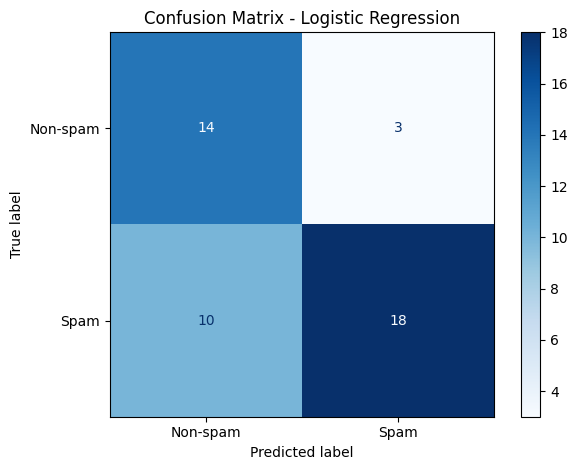

Confusion matrix:
[[14  3]
 [10 18]]


In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions, labels=[0, 1])

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-spam", "Spam"]
)

display_matrix.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()

plt.savefig(
    str(results_folder / "logistic_regression_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix:")
print(cm)

In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

metrics = {
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Score": [
        accuracy_score(y_test, predictions),
        precision_score(y_test, predictions, zero_division=0),
        recall_score(y_test, predictions, zero_division=0),
        f1_score(y_test, predictions, zero_division=0)
    ]
}

metrics_df = pd.DataFrame(metrics)

display(metrics_df.round(4))

metrics_df.to_csv(
    results_folder / "logistic_regression_metrics.csv",
    index=False
)

print("Metrics saved successfully!")

,Metric,Score
0,Accuracy,0.7111
1,Precision,0.8571
2,Recall,0.6429
3,F1-Score,0.7347


Metrics saved successfully!


In [35]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create the Decision Tree model
dt_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42,
    class_weight="balanced"
)

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions
dt_predictions = dt_model.predict(X_test)

# Evaluate the model
print("Decision Tree Accuracy:",
      round(accuracy_score(y_test, dt_predictions), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_predictions,
    labels=[0, 1],
    target_names=["Non-spam", "Spam"],
    zero_division=0
))

Decision Tree Accuracy: 0.7556

Classification Report:
              precision    recall  f1-score   support

    Non-spam       0.65      0.76      0.70        17
        Spam       0.84      0.75      0.79        28

    accuracy                           0.76        45
   macro avg       0.74      0.76      0.75        45
weighted avg       0.77      0.76      0.76        45



In [36]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

dt_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42,
    class_weight="balanced"
)

dt_model.fit(X_train, y_train)
dt_predictions = dt_model.predict(X_test)

print("Decision Tree Accuracy:",
      round(accuracy_score(y_test, dt_predictions), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_predictions,
    labels=[0, 1],
    target_names=["Non-spam", "Spam"],
    zero_division=0
))

Decision Tree Accuracy: 0.7556

Classification Report:
              precision    recall  f1-score   support

    Non-spam       0.65      0.76      0.70        17
        Spam       0.84      0.75      0.79        28

    accuracy                           0.76        45
   macro avg       0.74      0.76      0.75        45
weighted avg       0.77      0.76      0.76        45



In [39]:
from pyspark.ml.feature import VectorAssembler

# Copy the existing labeled dataset
spark_input = model_data.copy()

# Convert labels: -1 = Non-spam, 1 = Spam
spark_input["label"] = (
    spark_input["is_spammer"]
    .map({-1: 0, 1: 1})
    .astype(float)
)

# Remove the original target column
spark_input = spark_input.drop(columns=["is_spammer"])

# Create a Spark DataFrame
spark_df = spark.createDataFrame(spark_input)

# Select the input features
feature_columns = [
    "post_num",
    "follower_num",
    "followee_num",
    "gender_female",
    "gender_male"
]

# Combine the features into Spark MLlib's vector format
assembler = VectorAssembler(
    inputCols=feature_columns,
    outputCol="features"
)

model_df = assembler.transform(spark_df).select(
    "features", "label"
)

print("===== SPARK ML DATASET =====")
print("Total labeled records:", model_df.count())
print("Number of features:", len(feature_columns))

print("\nLabel distribution:")
model_df.groupBy("label").count().orderBy("label").show()

print("Sample records:")
model_df.show(5, truncate=False)

===== SPARK ML DATASET =====
Total labeled records: 179
Number of features: 5

Label distribution:
+-----+-----+
|label|count|
+-----+-----+
|  0.0|   66|
|  1.0|  113|
+-----+-----+

Sample records:
+---------------------------+-----+
|features                   |label|
+---------------------------+-----+
|[603.0,141.0,392.0,1.0,0.0]|1.0  |
|[149.0,463.0,952.0,0.0,1.0]|1.0  |
|[33.0,208.0,1833.0,0.0,1.0]|1.0  |
|[557.0,60.0,1528.0,0.0,1.0]|1.0  |
|[820.0,342.0,387.0,1.0,0.0]|0.0  |
+---------------------------+-----+
only showing top 5 rows



In [40]:
# Split labeled records: 75% training, 25% testing
train_df, test_df = model_df.randomSplit(
    [0.75, 0.25],
    seed=42
)

# Cache datasets to avoid repeated computation
train_df = train_df.cache()
test_df = test_df.cache()

print("===== TRAIN / TEST SPLIT =====")
print("Training records:", train_df.count())
print("Testing records:", test_df.count())

print("\nTraining label distribution:")
train_df.groupBy("label").count().orderBy("label").show()

print("Testing label distribution:")
test_df.groupBy("label").count().orderBy("label").show()

===== TRAIN / TEST SPLIT =====
Training records: 131
Testing records: 48

Training label distribution:
+-----+-----+
|label|count|
+-----+-----+
|  0.0|   55|
|  1.0|   76|
+-----+-----+

Testing label distribution:
+-----+-----+
|label|count|
+-----+-----+
|  0.0|   11|
|  1.0|   37|
+-----+-----+



In [41]:
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Create the Logistic Regression model
lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=100,
    regParam=0.01
)

# Train the model
lr_model = lr.fit(train_df)

# Predict on test data
lr_predictions = lr_model.transform(test_df)

# Evaluate accuracy
evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

lr_accuracy = evaluator.evaluate(lr_predictions)

print("===== SPARK MLlib LOGISTIC REGRESSION =====")
print("Test accuracy:", round(lr_accuracy, 4))
print("Test accuracy (%):", round(lr_accuracy * 100, 2), "%")

print("\nSample predictions:")
lr_predictions.select(
    "label", "prediction", "probability"
).show(10, truncate=False)

===== SPARK MLlib LOGISTIC REGRESSION =====
Test accuracy: 0.7083
Test accuracy (%): 70.83 %

Sample predictions:
+-----+----------+----------------------------------------+
|label|prediction|probability                             |
+-----+----------+----------------------------------------+
|1.0  |1.0       |[0.3545466415296171,0.6454533584703829] |
|1.0  |0.0       |[0.6187889981147914,0.3812110018852086] |
|0.0  |0.0       |[0.7205628315208717,0.27943716847912825]|
|0.0  |0.0       |[0.602603624877073,0.397396375122927]   |
|1.0  |1.0       |[0.17550687349621893,0.824493126503781] |
|1.0  |0.0       |[0.6549951928766924,0.3450048071233076] |
|1.0  |0.0       |[0.5963359377252073,0.4036640622747927] |
|1.0  |1.0       |[0.1875238283972242,0.8124761716027757] |
|0.0  |0.0       |[0.692717720779913,0.307282279220087]   |
|0.0  |0.0       |[0.6641652651028096,0.3358347348971904] |
+-----+----------+----------------------------------------+
only showing top 10 rows



Confusion Matrix:
[[11  0]
 [14 23]]


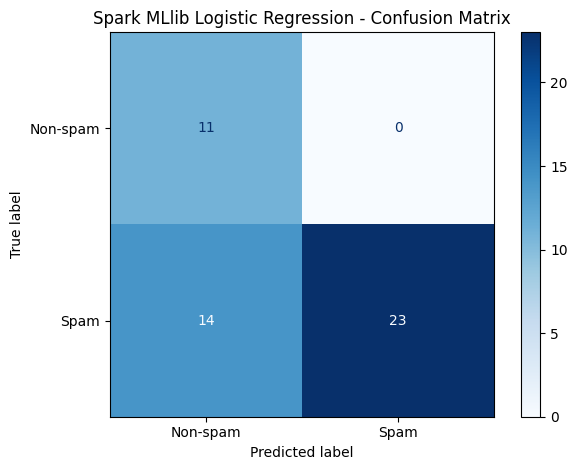

Saved to: c:\Users\Zaki\Social-Spam-Detection\results\spark_logistic_confusion_matrix.png


In [42]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np

# Calculate actual vs predicted counts in Spark
confusion_df = (
    lr_predictions
    .groupBy("label", "prediction")
    .count()
)

confusion_rows = confusion_df.collect()

# Matrix order: Non-spam (0), Spam (1)
cm = np.zeros((2, 2), dtype=int)

for row in confusion_rows:
    actual = int(row["label"])
    predicted = int(row["prediction"])
    cm[actual, predicted] = row["count"]

print("Confusion Matrix:")
print(cm)

# Plot the confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-spam", "Spam"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Spark MLlib Logistic Regression - Confusion Matrix")
plt.tight_layout()

results_folder.mkdir(parents=True, exist_ok=True)
plt.savefig(
    str(results_folder / "spark_logistic_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved to:", results_folder / "spark_logistic_confusion_matrix.png")

In [43]:
from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Create the Decision Tree classifier
dt = DecisionTreeClassifier(
    featuresCol="features",
    labelCol="label",
    maxDepth=5,
    seed=42
)

# Train the model
dt_model = dt.fit(train_df)

# Generate predictions on test data
dt_predictions = dt_model.transform(test_df)

# Evaluate accuracy
accuracy_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

dt_accuracy = accuracy_evaluator.evaluate(dt_predictions)

print("===== SPARK MLlib DECISION TREE =====")
print("Accuracy:", round(dt_accuracy, 4))
print("Accuracy (%):", round(dt_accuracy * 100, 2), "%")

print("\nSample predictions:")
dt_predictions.select(
    "label", "prediction"
).show(10)

print("\nDecision Tree structure:")
print(dt_model.toDebugString)

===== SPARK MLlib DECISION TREE =====
Accuracy: 0.6875
Accuracy (%): 68.75 %

Sample predictions:
+-----+----------+
|label|prediction|
+-----+----------+
|  1.0|       0.0|
|  1.0|       0.0|
|  0.0|       0.0|
|  0.0|       0.0|
|  1.0|       1.0|
|  1.0|       0.0|
|  1.0|       0.0|
|  1.0|       1.0|
|  0.0|       0.0|
|  0.0|       0.0|
+-----+----------+
only showing top 10 rows


Decision Tree structure:
DecisionTreeClassificationModel: uid=DecisionTreeClassifier_85ec344418b0, depth=5, numNodes=21, numClasses=2, numFeatures=5
  If (feature 2 <= 766.0)
   If (feature 1 <= 187.0)
    If (feature 2 <= 348.0)
     If (feature 0 <= 327.0)
      Predict: 0.0
     Else (feature 0 > 327.0)
      If (feature 1 <= 94.5)
       Predict: 0.0
      Else (feature 1 > 94.5)
       Predict: 1.0
    Else (feature 2 > 348.0)
     If (feature 1 <= 173.0)
      Predict: 1.0
     Else (feature 1 > 173.0)
      Predict: 0.0
   Else (feature 1 > 187.0)
    Predict: 0.0
  Else (feature 2 > 766.0)
   I

In [44]:
from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array

# Convert feature vectors into arrays for checking
feature_check = model_df.withColumn(
    "feature_array",
    vector_to_array("features")
)

negative_features = feature_check.filter(
    F.expr("exists(feature_array, x -> x < 0)")
).count()

print("===== NAIVE BAYES FEATURE CHECK =====")
print("Total records:", feature_check.count())
print("Records containing negative features:", negative_features)


===== NAIVE BAYES FEATURE CHECK =====
Total records: 179
Records containing negative features: 0


In [45]:
from pyspark.ml.classification import NaiveBayes
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

nb = NaiveBayes(
    featuresCol="features",
    labelCol="label",
    modelType="multinomial",
    smoothing=1.0
)

nb_model = nb.fit(train_df)
nb_predictions = nb_model.transform(test_df)

evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

nb_accuracy = evaluator.evaluate(nb_predictions)

print("===== SPARK MLlib NAIVE BAYES =====")
print("Accuracy:", round(nb_accuracy, 4))
print("Accuracy (%):", round(nb_accuracy * 100, 2), "%")

nb_predictions.select(
    "label", "prediction", "probability"
).show(10, truncate=False)

===== SPARK MLlib NAIVE BAYES =====
Accuracy: 0.75
Accuracy (%): 75.0 %
+-----+----------+-------------------------------------------+
|label|prediction|probability                                |
+-----+----------+-------------------------------------------+
|1.0  |1.0       |[4.663232330662795E-92,1.0]                |
|1.0  |1.0       |[4.701697409328098E-19,1.0]                |
|0.0  |0.0       |[0.9999859200520319,1.40799479681537E-5]   |
|0.0  |1.0       |[1.6498657043622023E-24,1.0]               |
|1.0  |1.0       |[2.804128937143583E-163,1.0]               |
|1.0  |1.0       |[3.4032914826827314E-13,0.9999999999996596]|
|1.0  |1.0       |[3.3934715335760916E-22,1.0]               |
|1.0  |1.0       |[4.853580276874608E-141,1.0]               |
|0.0  |0.0       |[0.9999999999953668,4.633164686976064E-12] |
|0.0  |0.0       |[0.9996528787692505,3.471212307494951E-4]  |
+-----+----------+-------------------------------------------+
only showing top 10 rows



In [46]:
from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array

feature_check = model_df.withColumn(
    "feature_array",
    vector_to_array("features")
)

negative_features = feature_check.filter(
    F.expr("exists(feature_array, x -> x < 0)")
).count()

print("Negative-feature records:", negative_features)

Negative-feature records: 0


In [47]:
from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array

feature_check = model_df.withColumn(
    "feature_array",
    vector_to_array("features")
)

negative_features = feature_check.filter(
    F.expr("exists(feature_array, x -> x < 0)")
).count()

print("Total records:", feature_check.count())
print("Records with negative features:", negative_features)

Total records: 179
Records with negative features: 0


In [48]:
from pyspark.ml.classification import NaiveBayes
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

nb = NaiveBayes(
    featuresCol="features",
    labelCol="label",
    modelType="multinomial",
    smoothing=1.0
)

nb_model = nb.fit(train_df)
nb_predictions = nb_model.transform(test_df)

evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

nb_accuracy = evaluator.evaluate(nb_predictions)

print("===== NAIVE BAYES RESULTS =====")
print("Accuracy:", round(nb_accuracy, 4))
print("Accuracy (%):", round(nb_accuracy * 100, 2), "%")

nb_predictions.select(
    "label", "prediction"
).show(10)

===== NAIVE BAYES RESULTS =====
Accuracy: 0.75
Accuracy (%): 75.0 %
+-----+----------+
|label|prediction|
+-----+----------+
|  1.0|       1.0|
|  1.0|       1.0|
|  0.0|       0.0|
|  0.0|       1.0|
|  1.0|       1.0|
|  1.0|       1.0|
|  1.0|       1.0|
|  1.0|       1.0|
|  0.0|       0.0|
|  0.0|       0.0|
+-----+----------+
only showing top 10 rows



In [49]:
import pandas as pd
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

# Prepare numeric regression data
regression_source = users_cleaned[
    ["post_num", "follower_num", "followee_num", "gender"]
].copy()

for col in ["post_num", "follower_num", "followee_num"]:
    regression_source[col] = pd.to_numeric(
        regression_source[col], errors="coerce"
    )

regression_source = regression_source.dropna(
    subset=["post_num", "follower_num", "followee_num", "gender"]
)

# Encode gender as numeric indicator columns
gender_encoded = pd.get_dummies(
    regression_source["gender"],
    prefix="gender",
    dtype=int
)

regression_data = pd.concat(
    [
        regression_source[["post_num", "follower_num", "followee_num"]]
        .reset_index(drop=True),
        gender_encoded.reset_index(drop=True)
    ],
    axis=1
)

# post_num is the numeric target to predict
regression_data = regression_data.rename(
    columns={"post_num": "label"}
)

feature_columns = [
    col for col in regression_data.columns if col != "label"
]

regression_spark_df = spark.createDataFrame(regression_data)

assembler = VectorAssembler(
    inputCols=feature_columns,
    outputCol="features"
)

regression_spark_df = assembler.transform(
    regression_spark_df
).select("features", "label")

# Split the data
reg_train, reg_test = regression_spark_df.randomSplit(
    [0.75, 0.25], seed=42
)

# Train Spark MLlib Linear Regression
linear_model = LinearRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=100
).fit(reg_train)

reg_predictions = linear_model.transform(reg_test)

# Evaluate using the required Unit VI metrics
for metric in ["r2", "rmse", "mae"]:
    evaluator = RegressionEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric
    )
    print(f"{metric.upper()}: {evaluator.evaluate(reg_predictions):.4f}")

print("\nSample predictions:")
reg_predictions.select(
    "label", "prediction"
).show(10, truncate=False)

R2: 0.0153
RMSE: 13149.1532
MAE: 4093.8073

Sample predictions:
+-----+------------------+
|label|prediction        |
+-----+------------------+
|44   |1484.070035351246 |
|42   |1696.5971030712135|
|40   |1581.922753648471 |
|117  |4603.2211852266455|
|246  |1719.5399274836684|
|48   |1583.4603414337255|
|557  |3883.068173514283 |
|209  |1650.7344187677768|
|756  |4603.228269608149 |
|121  |1471.8477452881664|
+-----+------------------+
only showing top 10 rows



----------------------------------------
Exception occurred during processing of request from ('127.0.0.1', 64460)
Traceback (most recent call last):
  File "C:\Users\Zaki\AppData\Local\Programs\Python\Python310\lib\socketserver.py", line 316, in _handle_request_noblock
    self.process_request(request, client_address)
  File "C:\Users\Zaki\AppData\Local\Programs\Python\Python310\lib\socketserver.py", line 347, in process_request
    self.finish_request(request, client_address)
  File "C:\Users\Zaki\AppData\Local\Programs\Python\Python310\lib\socketserver.py", line 360, in finish_request
    self.RequestHandlerClass(request, client_address, self)
  File "C:\Users\Zaki\AppData\Local\Programs\Python\Python310\lib\socketserver.py", line 747, in __init__
    self.handle()
  File "c:\Users\Zaki\Social-Spam-Detection\.venv\lib\site-packages\pyspark\accumulators.py", line 295, in handle
    poll(accum_updates)
  File "c:\Users\Zaki\Social-Spam-Detection\.venv\lib\site-packages\pyspark\accumul

What these metrics mean:
- R²: how well the model explains variation in post counts.
- RMSE: typical prediction error, with larger errors penalized more heavily.
- MAE: average absolute prediction error.
These are regression metrics, not classification metrics. Run the cell and send me the output. Next we'll cover K-means, then finish the remaining Unit VI evaluation and theory topics.